# Programmation Python  pour les mathématiques

**Julien Guillod**, [Sorbonne Université](http://www.sorbonne-universite.fr/),
Licence <a href="https://creativecommons.org/licenses/by-nc-nd/4.0/">CC BY-NC-ND</a>

L'entier des chapitres est disponible au format
[HTML](https://python.guillod.org//) et [PDF](https://python.guillod.org//python.pdf).
Ce notebook peut également être exécuté sur [GESIS](https://notebooks.gesis.org/binder/v2/gh/guillod/python/master?filepath=chap09.ipynb).

# 9 Probabilités et Statistiques

<div id="ch:proba-stats"></div>

Premièrement la statistique de la proportion de nombres commençant par un certain chiffre sera étudiée. Finalement deux modèles probabilistes importants seront introduits.

**Concepts abordés:**

* statistiques et probabilités

* série harmonique aléatoire

* marche aléatoire

* histogrammes

* importation de données

* optimisation par compilation

* percolation

* transition de phase



# Exercice 9.1: Série harmonique de signe aléatoire


Le but de cet exercice est de simuler la convergence d'une série harmonique donc le signe est tiré aléatoirement. Plus précisément si $(X_i)_{i\in\mathbb{N}}$ est une suite de variables aléatoires indépendantes valant $-1$ ou $1$ avec probabilité $\frac{1}{2}$, alors on définit la somme partielle

$$
W_0 = 0 \,, \qquad\qquad W_n = \sum_{i=1}^n \frac{X_i}{i} \,,
$$

et la question est de déterminer si la suite $(W_n)_{n\in\mathbb{N}}$ converge et si oui vers quoi.

**a)**
Écrire une fonction `sign()` qui simule la variable aléatoire $X_i$.



In [75]:
import numpy as np
import matplotlib.pyplot as plt

In [43]:
def sign():
    # np.random.random_sample()
    return 1 if np.random.binomial(1,1/2) else -1
print(sign())

-1



**b)**
Écrire une fonction `simulate(n)` qui retourne une liste avec une réalisation de $(W_1,W_2,\dots,W_n)$.



In [54]:
def SigmaW(n):
    s = 0
    for i in range(1, n + 1):
            s += sign()*1/i
    return s

In [57]:
def simulate(n):
    W=list()
    W.insert(0,0)
    for k in range(1,n + 1):
        W.append(SigmaW(k))
    return W
print(simulate(10))
print(simulate(10))

[0, -1.0, -0.5, 0.16666666666666669, -2.083333333333333, 0.7833333333333332, 1.2166666666666666, 0.3071428571428571, -2.0511904761904765, 1.273412698412698, 0.054365079365079366]
[0, -1.0, -0.5, -1.1666666666666667, 1.0833333333333333, -1.2166666666666668, 1.7833333333333334, 1.6404761904761906, -0.19880952380952374, -0.20992063492063492, -0.9765873015873016]



**c)**
Faire la représentation graphique de la fonction $n \mapsto W_n$ pour différentes réalisations par exemple pour $0\leq n\leq 1000$ et émettre une conjecture quant à la convergence de la suite $(W_n)_{n\in\mathbb{N}}$.



[-1.9379257502032912, -1.846550651329679, -0.3782919189091185, 0.14605222235304055, 0.6022514917228846, -2.0475208564680925, -0.6148057119867566, 0.5797632304423458, 1.013672618428143, 0.75362422291938, 1.5704826426091258, 0.5169725807399316, 0.40042448305593104, -0.26482361194860876, -0.6535209184640699, 1.162172698960116, -1.0534277848004228, -0.6301490101603305, -0.3303912541279407, -0.7840402483354055, -0.8883673984840063, 1.3810088751288987, 1.2408545439278078, 0.9188745411421785, 1.2166978135010544, -0.9839160889729374, -1.5057956495824745, -1.6999497456465047, -0.3133358421208362, 0.4079313083546281, 0.010040328425058278, -1.768656269667824, 1.4649395850824845, -1.7627871922718192, -0.9258279807990165, 2.324538164798653, 0.5732043187713295, 1.4396478199483518, -0.771481246589064, -1.9591379032229719, -0.23062890032836902, -0.871256783735559, -1.706588410785456, 2.3275957103727296, -1.3815427343602025, -1.932118324102951, 0.45485210606781823, -1.3942300453233751, -1.3186559973886

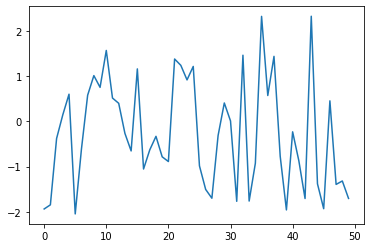

In [79]:
W_n = list()
n = np.arange(50)
for _ in range(50):
    W_n.append(simulate(100))
# print(W_n)
l = [W_n[k][45] for k in range(50)]
plt.plot(n,l)
# représentation de W_45
print(l)


**d)**
<span style="color:red">!</span>
Déterminer l'histogramme de $W_{1000}$ pour $10^4$ ou $10^5$ réalisations pour avoir une idée de la loi de la variable aléatoire limite.



# Exercice 9.2: Loi de Benford

La loi de Benford prédit que statistiquement dans une liste de nombres donnés, la probabilité qu'un de ces nombres commence par le chiffre 1 est plus importante que celle qu'un nombre commence par le chiffre 9. Plus précisément la loi de Benford prédit que la probabilité qu'un nombre commence par le chiffre $d$ est:

$$
p_d = \log_{10}\bigg(1+\frac{1}{d}\bigg) \,,
$$

où $\log_{10}$ désigne le logarithme en base 10.
Il est possible de vérifier que la loi de Benford est la seule qui reste invariante par changement d'unités, *i.e.* en multipliant les nombres de la liste par une constante les probabilités précédentes restent inchangées.

**a)**
Écrire une fonction `firstdigit(n)` qui donné un nombre `n` retourne son premier chiffre et une fonction `occurrences(liste)` qui retourne le nombre d'occurrences des premiers chiffres de `liste`.

**Indication:**
Faire en sorte que la fonction `occurrences` fonctionne même si la liste contient des zéros en les ignorant.





**b)**
Vérifier si la loi de Benford semble satisfaite pour la suite des nombres $(2^n)_ {n\in\mathbb{N}}$ en comparant l'histogramme empirique avec la loi de Benford.




**c)**
Vérifier si la loi de Benford semble satisfaite pour la suite des nombres $(3n+1)_ {n\in\mathbb{N}}$.




**d)**
En allant sur le site de l'INSEE à l'adresse: <https://insee.fr/fr/statistiques/4171341?sommaire=4171351>, télécharger le fichier au format TXT contenant les données de la population par sexe et âge regroupé (POP1A). Importer ces données pour avoir la population par code postal, sexe et tranche d'âge.

**Indication:**
La documentation sur comment lire un fichier est disponible [ici](https://docs.python.org/fr/3/tutorial/inputoutput.html#reading-and-writing-files). A noter que les fichiers TXT de l'INSEE sont encodés au format ISO-8859-1.




**e)**
Déterminer si la liste de toutes les populations par commune, sexe et âge suit la loi de Benford.




**f)**
Sommer les données précédentes pour obtenir la liste des populations par commune et déterminer si elle suit la loi de Benford.




**g)**
<span style="color:red">!!</span> Lire la documentation du module Pandas disponible [ici](https://pandas.pydata.org/docs/) et l'utiliser pour refaire les deux questions précédentes mais avec le fichier de population POP1B avec les âges non-regroupés.

**Indication:**
Utiliser la fonction `read_csv` de Pandas.





**h)**
<span style="color:red">!!</span> En allant sur le site de l'INSEE ou autre télécharger votre jeu de données préféré, et tester s'il suit la loi de Benford.

**Indication:**
Utiliser par exemple les comptes détaillés de l'Etat disponible [ici](https://www.data.gouv.fr/fr/datasets/donnees-de-comptabilite-generale-de-letat/).



# Exercice 9.3: Ruine du joueur

Le but est de simuler l'évolution de la somme d'argent d'un joueur jouant à pile ou face. A chaque lancé le joueur gagne un franc si c'est pile et en perd un si c'est face. La probabilité d'obtenir pile est notée $p$, celle d'obtenir face $q$. En particulier $p=q=\frac{1}{2}$ si la pièce est équilibrée.

Mathématiquement, la somme $S_i$ possédée par le joueur au temps $i$ est donné par une marche aléatoire:

$$
S_{i}=\begin{cases}
0\,, & \text{si}\:S_{i-1}=0\,,\\ 
S_{i-1}+X_{i}\,, & \text{si}\:S_{i-1}\geq1\,,
\end{cases}
$$

où les $(X_i)_ {i\geq1}$ sont des variables aléatoires indépendantes de loi $\mathbb{P}(X_i=1) = p$ et $\mathbb{P}(X_i=-1) = q$.

**a)**
Écrire une fonction `simulate(p,k,N)` qui génère une réalisation de longueur $N$ du processus à partir de $S_0=k$, c'est-à-dire qui retourne $(S_0,S_1,S_2,\dots,S_N)$. Représenter graphiquement plusieurs réalisations.




**b)**
Simuler un joueur qui commençant avec une somme $k$ joue jusqu'à tout perdre ou avoir la somme $n > k$.




**c)**
Si $T$ désigne le temps auquel le jeu s'arrête, *i.e.* lorsque $S_T = 0$ ou $S_T = n$, retrouver par simulation les résultats théoriques sur le temps moyen:

$$
\mathbb{E}(T)=\begin{cases}
k(n-k)\,, & \text{si}\:p=q\,,\\ 
\dfrac{n}{p-q}\dfrac{1-\rho^{k}}{1-\rho^{n}}-\dfrac{k}{p-q}\,, & \text{si}\:p\neq q\,,
\end{cases}
$$

et le lieu de sortie:

$$
\mathbb{P}(S_{T}=0)=\begin{cases}
\dfrac{n-k}{n}\,, & \text{si}\:p=q\,,\\ 
\dfrac{\rho^{k}-\rho^{n}}{1-\rho^{n}}\,, & \text{si}\:p\neq q\,,
\end{cases}
$$

où $\rho = q/p$. Pour cela on pourra faire un graphique de ces quantités en fonction de $p$ ou se contenter de considérer le cas $p=q=\frac{1}{2}$.



# Exercice 9.4: <span style="color:red">!</span> Percolation

Le but est d'étudier un modèle de percolation dans un milieu poreux. Le milieu est modélisé par une matrice aléatoire de booléens qui détermine les sites qui peuvent être envahi par l'eau et ceux qui sont imperméables. Une matrice percole s'il existe un chemin d'eau allant de la ligne supérieure vers la ligne inférieure. Dans les exemples suivants, les entrées d'une matrice pouvant être envahies par l'eau sont colorées et les entrées effectivement remplies d'eau sont en bleu. La première matrice ne percole pas alors que la seconde oui:

<center><img src="https://python.guillod.org/fig/percolation-def.png" style="width:90%;max-width:800px;"></center>

**a)**
Écrire une fonction `generate(n,p)` qui génère une matrice de booléens de taille $n \times n$ telle que chaque entrée ait probabilité $p$ d'être juste et $1-p$ d'être fausse.

**Indication:**
La fonction `numpy.random.binomial` peut être utile.




**b)**
Définir une fonction `fill(isopen)` qui donné une matrice de booléens renvoie une autre matrice de booléens avec les entrées envahies par l'eau.

**Indication:**
Définir une matrice de booléens `isfull` pour stocker si une entrée est remplie par l'eau ou pas, puis définir une fonction récursive `flow(isopen, isfull, i, j)` permettant d'envahir toutes les entrées possibles à partir de $(i,j)$.




**c)**
A l'aide de Matplotlib représenter le remplissage de différentes matrices générées aléatoirement.




**d)**
Définir une fonction `percolate(isopen)` permettant de déterminer si une matrice de booléens percole ou non.




**e)**
<span style="color:red">!!</span> Calculer le temps nécessaire pour déterminer si une matrice de taille $50 \times 50$ avec $p=0.9$ percole ou non. Lire la documentation du module `numba` pour réduire le temps de calcul en compilant une des fonctions: <https://numba.pydata.org/>.

**Indication:**
La fonction qui est la plus utilisée est la fonction récursive, donc c'est celle-ci qu'il faut optimiser en la compilant.




**f)**
En faisant des statistiques, déterminer la probabilité qu'une matrice aléatoire booléenne de taille $n \times n$ avec probabilité $p$ percole. Étudier cette probabilité en fonction de $p$ et de $n$.

**Indication:**
Faire le graphique de cette probabilité de percolation en fonction de $p$ pour différentes valeurs de $n$.

**Réponse:**
Dans la limite des $n$ très grands, une matrice percole presque surement si $p>0.592746$ et presque jamais sinon.




**g)**
<span style="color:red">!!!</span> Les statistiques effectuées au point précédent sont un exemple typique de calculs pouvant être facilement exécutés en parallèle, car chaque cas est indépendant des autres. Paralléliser l'algorithme précédent de manière à utiliser tous les cœurs de votre processeur, par exemple à l'aide du module [`mpi4py`](http://mpi4py.readthedocs.io/).

**Indication:**
L'utilisation de Jupyter Lab pour faire du calcul parallèle est assez complexe à mettre en œuvre, il vaut mieux utiliser la ligne de commande pour exécuter un script en parallèle, par exemple pour quatre cœurs: `mpirun -n 4 script.py`. A noter que [Open MPI](https://www.open-mpi.org/) ou [MPICH](https://www.mpich.org/) doit être installé sur votre ordinateur.

